In [3]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import cm
import torch
import os

import sys
sys.path.insert(0, '../trainingdata')
from datasaver import *
sys.path.insert(0, '../testproblems/tdarcy')
from manufacturedsolutions import *
sys.path.insert(0, '../ml')
from modelloader import loadmodelfromlabel
from NeuralOperator import NeuralOperator
from customlosses import *
from quadrature import *
from customlayers import discretize_functions
from basisfunctions import *

In [2]:
%load_ext autoreload
%autoreload 2

In [8]:
from NeuralOperator import NeuralOperator

logdir = '../../../nnlogs'
device = 'cuda:3'

sublogdir = 'dataNGO_solutions'

projection = loadmodelfromlabel(model=NeuralOperator, label='dataNGO', logdir=logdir, sublogdir=sublogdir, device=device)
projection.hparams['modeltype'] = 'projection'
projection.hparams['dtype'] = torch.float64
projection.__init__(projection.hparams)

FEM = loadmodelfromlabel(model=NeuralOperator, label='dataNGO', logdir=logdir, sublogdir=sublogdir, device=device)
FEM.hparams['modeltype'] = 'FEM'
FEM.hparams['dtype'] = torch.float64
FEM.hparams['Neumannseries'] = False
FEM.hparams['Neumannseries_order'] = None
FEM.hparams['project_materialparameters'] = True
FEM.hparams['gamma_stabilization'] = 0
FEM.__init__(FEM.hparams)

stabFEM = loadmodelfromlabel(model=NeuralOperator, label='dataNGO', logdir=logdir, sublogdir=sublogdir, device=device)
stabFEM.hparams['modeltype'] = 'FEM'
stabFEM.hparams['dtype'] = torch.float64
stabFEM.hparams['Neumannseries'] = False
stabFEM.hparams['Neumannseries_order'] = None
stabFEM.hparams['project_materialparameters'] = True
stabFEM.hparams['project_initialcondition'] = False
stabFEM.hparams['gamma_stabilization'] = 100
stabFEM.__init__(stabFEM.hparams)

stabFEM_p = loadmodelfromlabel(model=NeuralOperator, label='dataNGO', logdir=logdir, sublogdir=sublogdir, device=device)
stabFEM_p.hparams['modeltype'] = 'FEM'
stabFEM_p.hparams['dtype'] = torch.float64
stabFEM_p.hparams['Neumannseries'] = False
stabFEM_p.hparams['Neumannseries_order'] = None
stabFEM_p.hparams['project_materialparameters'] = True
stabFEM_p.hparams['project_initialcondition'] = True
stabFEM_p.hparams['gamma_stabilization'] = 100
stabFEM_p.__init__(stabFEM_p.hparams)

dataNGO_solutions = loadmodelfromlabel(model=NeuralOperator, label='dataNGO_S_C_rhomax', logdir=logdir, sublogdir='dataNGO_solutions', device=device)
dataNGO_coefficients = loadmodelfromlabel(model=NeuralOperator, label='dataNGO_S_rhomax_C', logdir=logdir, sublogdir='dissipation', device=device)
dataNGO_boundary = loadmodelfromlabel(model=NeuralOperator, label='dataNGO_solutions', logdir=logdir, sublogdir='dataNGO_boundary', device=device)
dataNGO_boundarycoeffs = loadmodelfromlabel(model=NeuralOperator, label='dataNGO_boundarycoeffs_M0T', logdir=logdir, sublogdir='dataNGO_coeffs', device=device)

dataNGO_IC = loadmodelfromlabel(model=NeuralOperator, label='dataNGO_coeffs_projectoninterior', logdir=logdir, sublogdir='project_initialcondition', device=device)

FNO = loadmodelfromlabel(model=NeuralOperator, label='FNO', logdir=logdir, sublogdir='tdd_new', device=device)

modeldict = {#'Projection': projection,
            #'FEM': FEM,
             'Stabilized FEM': stabFEM,
            # 'Stabilized FEM p': stabFEM_p,
            #'FNO': FNO,
            'Data NGO': dataNGO_IC}
            # 'Data NGO (solutions)': dataNGO_solutions}
            # 'Data NGO (solutions, uniform quadrature)': dataNGO_solutions_uniform,
            # 'Data NGO (coefficients)': dataNGO_coefficients,
            # 'Data NGO (boundary solutions)': dataNGO_boundary}
            # 'Data NGO (boundary coefficients)': dataNGO_boundarycoeffs}

/data/storage8/prins/prins/phd/git/ngo-pde-gk/analysisnotebooks/../testproblems/tdarcy/NeuralOperator.py:42: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.x_0 = torch.tensor(self.hparams.get('x_0', x_0), dtype=self.dtype, device=self.used_device)


0
1
2
3
4
5
6
7
8
9


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


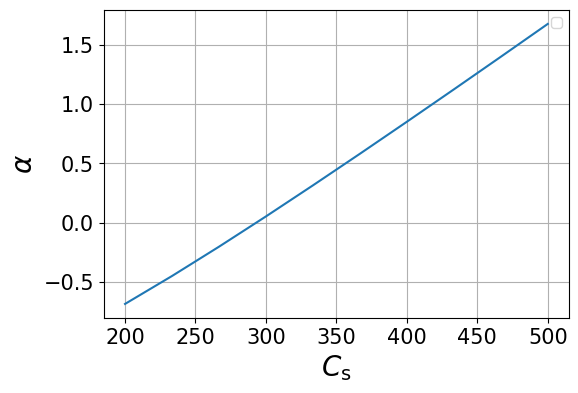

In [38]:
N_samples = 1

alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low

C_ss = np.linspace(200,500,10)
alphas = np.zeros(len(C_ss))

size_title = 20
size_ticklabels = 15
size_axeslabels = 20

# quadrature = GaussLegendreQuadrature(n_elements=[3,30,30], Q=[3,30,30])
quadrature = UniformQuadrature(Q=[2,100,100])
x = quadrature.xi
x_scaled = np.copy(x)
x_scaled[:,0] = x_scaled[:,0]*projection.hparams['Dt']
w = quadrature.w
w = w*projection.hparams['Dt']

# linestyles=['-','-','--','--','--','--','--','--','--','--','--']
# colors = ['black','grey','C3','C6','C4','C5','C0','C1','C2']
linestyles=['--','--','--','--','--','--','--','--','--']
colors = ['C3','C6','C4','C5','C0','C1','C2']

dataset = ManufacturedSolutionsSet(N_samples=N_samples, variables=['t','x','x'], l_min=[1,1,1], l_max=[1,1,1])
theta = dataset.theta
f = dataset.f
etat = dataset.etat
etab = dataset.etab
gl = dataset.gl
gr = dataset.gr
u = dataset.u
u0 = dataset.u0
m=0
    
for i in range(len(C_ss)):
    print(i)
    stabFEM.hparams['gamma_stabilization'] = C_ss[i]
    alphas[i] = stabFEM.compute_alpha(theta, f, etab, etat, gl, gr, u0, u)

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'$C_{\mathrm{s}}$', fontsize=size_axeslabels)
ax.set_ylabel(r'$\alpha$', fontsize=size_axeslabels)
# ax.set_yscale('log')
# ax.set_xlim(0, 1.05)
# ax.set_ylim(1e-7,1e2)
# ax.set_yticks([1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1,1e0,1e1,1e2])
ax.grid()
# ax.set_title('FNO', fontsize=size_title)
plots.append(ax.plot(C_ss,  alphas))
plt.legend(fontsize=10, ncols=1)
# legend1 = ax.legend(handles=plots[0:2],fontsize=10, ncols=1, loc='lower left')
# plt.gca().add_artist(legend1)
# legend2 = ax.legend(handles=plots[2:],fontsize=10, ncols=2, loc='upper right')
# plt.gca().add_artist(legend2)

# plt.savefig("lengthscales.svg", bbox_inches='tight')#, transparent=True)
# plt.savefig("lengthscales.pdf", bbox_inches='tight')#, transparent=True)

plt.show()

In [48]:
stabFEM.hparams['gamma_stabilization'] = 270

0
1
2
3
4
5
6
7
8
9


No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


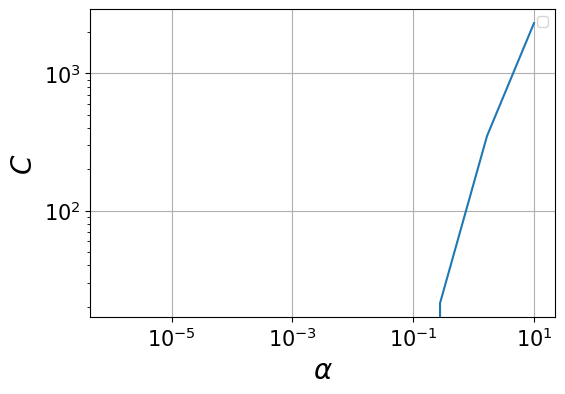

In [ ]:
N_samples = 1

alpha = 0.05
q_low = alpha/2
q_high = 1 - q_low

alphas = np.logspace(-6,1,10)
C_ABCs = np.zeros(len(alphas))

size_title = 20
size_ticklabels = 15
size_axeslabels = 20

# quadrature = GaussLegendreQuadrature(n_elements=[3,30,30], Q=[3,30,30])
quadrature = UniformQuadrature(Q=[2,100,100])
x = quadrature.xi
x_scaled = np.copy(x)
x_scaled[:,0] = x_scaled[:,0]*projection.hparams['Dt']
w = quadrature.w
w = w*projection.hparams['Dt']

# linestyles=['-','-','--','--','--','--','--','--','--','--','--']
# colors = ['black','grey','C3','C6','C4','C5','C0','C1','C2']
linestyles=['--','--','--','--','--','--','--','--','--']
colors = ['C3','C6','C4','C5','C0','C1','C2']

dataset = ManufacturedSolutionsSet(N_samples=N_samples, variables=['t','x','x'], l_min=[1,1,1], l_max=[1,1,1])
theta = dataset.theta
f = dataset.f
etat = dataset.etat
etab = dataset.etab
gl = dataset.gl
gr = dataset.gr
u = dataset.u
u0 = dataset.u0
m=0
    
for i in range(len(alphas)):
    print(i)
    stabFEM.hparams['alpha'] = alphas[i]
    
    C_ABCs[i] = stabFEM.compute_C_ABC(theta, f, etab, etat, gl, gr, u0, u)

fig, ax = plt.subplots(1,1, figsize=(6, 4))
fig.subplots_adjust(left=None, bottom=None, right=None, top=None, wspace=0.4, hspace=0.4)

plots = []
m=0
ax.tick_params(axis='both', labelsize=size_ticklabels)
ax.set_xlabel(r'$\alpha$', fontsize=size_axeslabels)
ax.set_ylabel(r'$C$', fontsize=size_axeslabels)
ax.set_xscale('log')
ax.set_yscale('log')
# ax.set_xlim(0, 1.05)
# ax.set_ylim(1e-7,1e2)
# ax.set_yticks([1e-7,1e-6,1e-5,1e-4,1e-3,1e-2,1e-1,1e0,1e1,1e2])
ax.grid()
# ax.set_title('FNO', fontsize=size_title)
plots.append(ax.plot(alphas,  C_ABCs))
plt.legend(fontsize=10, ncols=1)
# legend1 = ax.legend(handles=plots[0:2],fontsize=10, ncols=1, loc='lower left')
# plt.gca().add_artist(legend1)
# legend2 = ax.legend(handles=plots[2:],fontsize=10, ncols=2, loc='upper right')
# plt.gca().add_artist(legend2)

# plt.savefig("lengthscales.svg", bbox_inches='tight')#, transparent=True)
# plt.savefig("lengthscales.pdf", bbox_inches='tight')#, transparent=True)

plt.show()